# Pandas Assignment: Bengaluru Real Estate

**Case study:** *Which Bengaluru localities are overpriced?*

| | |
|---|---|
| **Name** |Naveen Narendra Samal |
| **Roll No.** | SCLU326027 |
| **Total marks** | 10 (Assignment 5 + Viva 5) |
| **Dataset** | `Bengaluru_House_Data.csv` (put it in the same folder as this notebook) |

## Scenario
You have joined a real-estate analytics startup. The team gives you a raw listing file scraped from the web and asks you to clean it, explore it, and prepare it for a price-prediction model. Your manager also wants a short list of insights.

## Data dictionary

| Column | Meaning | Type |
|---|---|---|
| `area_type` | Type of area (e.g. Super built-up Area, Plot Area) | Categorical |
| `availability` | Ready to move, or a possession date | Categorical |
| `location` | Locality in Bengaluru | Categorical |
| `size` | Number of bedrooms, written as text (e.g. "2 BHK") | Categorical (text) |
| `society` | Society / project name | Categorical |
| `total_sqft` | Area in square feet (may be messy) | Numerical (stored as text) |
| `bath` | Number of bathrooms | Numerical |
| `balcony` | Number of balconies | Numerical |
| `price` | Price in **lakhs** of rupees | Numerical |

## Rules
1. Use only `pandas`, `numpy` and `matplotlib`. Write scaling formulas yourself (no scikit-learn).
2. Never edit the CSV by hand. All cleaning must be done in code.
3. Work on a copy: keep `raw = pd.read_csv(...)` untouched and clean `df = raw.copy()`.
4. **Every cleaning decision needs a one-line reason** in the answer cell. Code without reasoning gets half marks.
5. Run the notebook from top to bottom (Kernel > Restart and Run All) before submitting.
6. Submit the `.ipynb` file named `RollNo_Name_Bengaluru.ipynb`.

## Marks split

| Component | Marks |
|---|---|
| Assignment (this notebook) | 5 |
| Viva (based on your own notebook) | 5 |
| **Total** | **10** |

The assignment is marked on the whole notebook: correct code, visible output and a written reason for every cleaning decision.

## Setup

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

raw = pd.read_csv('Bengaluru_House_Data.csv')
df = raw.copy()
df.head()

,area_type,availability,location,size,society,total_sqft,bath,balcony,price
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,Coomee,1056,2.0,1.0,39.07
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,Theanmp,2600,5.0,3.0,120.00
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,NaN,1440,2.0,3.0,62.00
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,Soiewre,1521,3.0,1.0,95.00
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,NaN,1200,2.0,1.0,51.00


---
## Part A: Understand the data

**A1.** Print the shape, the data type of every column, and a summary that includes both numerical and categorical columns.

In [7]:
# YOUR CODE HERE
print("(rows,column) =",df.shape)
print(df.dtypes)
raw.describe(include='all')

(rows,column) = (13320, 9)
area_type        object
availability     object
location         object
size             object
society          object
total_sqft       object
bath            float64
balcony         float64
price           float64
dtype: object


,area_type,availability,location,size,society,total_sqft,bath,balcony,price
count,13320,13320,13319,13304,7818,13320,13247.000000,12711.000000,13320.000000
unique,4,81,1305,31,2688,2117,NaN,NaN,NaN
top,Super built-up Area,Ready To Move,Whitefield,2 BHK,GrrvaGr,1200,NaN,NaN,NaN
freq,8790,10581,540,5199,80,843,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,NaN,NaN,2.692610,1.584376,112.565627
std,NaN,NaN,NaN,NaN,NaN,NaN,1.341458,0.817263,148.971674
min,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,0.000000,8.000000
25%,NaN,NaN,NaN,NaN,NaN,NaN,2.000000,1.000000,50.000000
50%,NaN,NaN,NaN,NaN,NaN,NaN,2.000000,2.000000,72.000000
75%,NaN,NaN,NaN,NaN,NaN,NaN,3.000000,2.000000,120.000000


**A2.** List which columns are numerical and which are categorical *as they are stored right now*. One column is numerical in meaning but stored as text. Name it.

**Your answer / justification:**

**Numerical columns are** :`bath` (float64), `balcony` (float64), `price` (float64).
**Categorical / Text columns are :** `area_type` (object), `availability` (object), `location` (object), `size` (object), `society` (object), `total_sqft` (object).
**Numerical in meaning but stored as text:** `total_sqft`. Because it represent the square foot ,which is numerical measurement.

---
## Part B: Data quality audit

**B1.** Show the number **and percentage** of missing values in each column, sorted from highest to lowest.

In [11]:
# YOUR CODE HERE
missingvalues=df.isnull().sum()
per=(missingvalues/len(df)*100)
missing_values_per = pd.DataFrame({
    "missingvalues": missingvalues,
    "per": per
}).sort_values(by='missingvalues', ascending=False)

missing_values_per



,missingvalues,per
society,5502,41.306306
balcony,609,4.572072
bath,73,0.548048
size,16,0.120120
location,1,0.007508
area_type,0,0.000000
availability,0,0.000000
total_sqft,0,0.000000
price,0,0.000000


**B2.** How many rows are exact duplicates? Show a few of them.

In [13]:
# YOUR CODE HERE
print("duplicated rows=",df.duplicated().sum())
df[df.duplicated(keep=False)].head(5)

duplicated rows= 529


,area_type,availability,location,size,society,total_sqft,bath,balcony,price
8,Super built-up Area,Ready To Move,Marathahalli,3 BHK,NaN,1310,3.0,1.0,63.25
33,Super built-up Area,Ready To Move,Raja Rajeshwari Nagar,3 BHK,GrrvaGr,1693,3.0,3.0,57.39
35,Super built-up Area,21-Dec,Kanakpura Road,2 BHK,PrarePa,700,2.0,1.0,36.00
38,Super built-up Area,Ready To Move,Chikkalasandra,3 BHK,NaN,1290,2.0,2.0,56.12
55,Super built-up Area,Ready To Move,Begur Road,2 BHK,Dhalsh,1200,2.0,2.0,44.00


**B3.** Write a short audit report (3 to 5 lines): which columns have the biggest problems and what you plan to do about each.

**Your answer / justification:**
1. **`society`**: Has 5,502 missing values (over 41.3%), making imputation highly speculative and prone to error. Plan: Drop the entire column.
2. **`total_sqft` & `size`**: Stored as messy text. `total_sqft` contains range strings and unit text; `size` combines numbers with bedroom labels. Plan: Convert `total_sqft` to numeric via custom averaging function and extract integer `bhk` from `size`.
3. **`balcony` & `bath`**: Modest missing values (~4.5% in balcony and ~0.5% in bath). Plan: Impute both using median values to preserve listing counts without skewing distributions.
4. **`location`**: Has 1 missing value and minor whitespace/capitalization variations. Plan: Drop the 1 missing row and strip trailing/leading whitespace.
5. **Duplicate Rows**: 529 exact duplicate records exist. Plan: Remove all duplicate rows to avoid giving artificial weight to repeated listings.


---
## Part C: Cleaning

**C1.** Remove duplicate rows. Print the shape before and after.

In [14]:
# YOUR CODE HERE
shape_before = df.shape
df = df.drop_duplicates()
shape_after = df.shape

print(f"Shape before dropping duplicates: {shape_before}")
print(f"Shape after dropping duplicates:  {shape_after}")
print(f"Removed {shape_before[0] - shape_after[0]} duplicate rows.")


Shape before dropping duplicates: (13320, 9)
Shape after dropping duplicates:  (12791, 9)
Removed 529 duplicate rows.


**C2.** One column has so many missing values that filling it would be unreliable. Identify it, drop it, and justify.

In [15]:
# YOUR CODE HERE
print(f"Missing percentage in 'society': {(raw['society'].isnull().sum() / len(raw)) * 100:.2f}%")
df = df.drop(columns=['society'])
print("Remaining columns:", df.columns.tolist())

Missing percentage in 'society': 41.31%
Remaining columns: ['area_type', 'availability', 'location', 'size', 'total_sqft', 'bath', 'balcony', 'price']


**Your answer / justification:**
The `society` column is missing in 5,502 entries (~41.3% of the dataset). Because housing society names are high-cardinality categorical identifiers, any imputation (such as mode or placeholder) would introduce severe artificial noise. Moreover, society is non-essential for locality-level macro pricing analysis, so dropping it is the most sound and reliable decision.


**C3.** Handle the remaining missing values in `location`, `size`, `bath` and `balcony`.
For **each** column, choose drop, fill with a constant, or fill with mean/median/mode, and justify.

*Hint: think about which columns are categorical and which are numerical, and about how many rows each choice would affect.*

In [16]:
# YOUR CODE HERE
print("Missing counts before handling:")
print(df[['location', 'size', 'bath', 'balcony']].isnull().sum())

df = df.dropna(subset=['location', 'size'])

df['bath'] = df['bath'].fillna(df['bath'].median())
df['balcony'] = df['balcony'].fillna(df['balcony'].median())

print("\nMissing counts after handling:")
print(df[['location', 'size', 'bath', 'balcony']].isnull().sum())


Missing counts before handling:
location      1
size         16
bath         73
balcony     605
dtype: int64

Missing counts after handling:
location    0
size        0
bath        0
balcony     0
dtype: int64


**Your answer / justification:**

- **`location` (Drop)**: Only 1 row is missing locality. Geographical location is fundamental to real-estate pricing and cannot be guessed. Dropping 1 row has zero statistical penalty.
- **`size` (Drop)**: Only 16 rows lack size. Bedroom count determines space and price; imputing it arbitrarily could corrupt downstream `sqft_per_bhk` metrics. Dropping 16 rows (<0.13%) guarantees data integrity.
- **`bath` (Fill with median)**: Missing in ~73 rows (0.5%). Median (2 bathrooms) is robust against outliers and accurately reflects standard apartment configurations without dropping valid listings.
- **`balcony` (Fill with median)**: Missing in ~600 rows (4.5%). Imputing with the median (1 balcony) prevents unnecessary data loss and matches the mode/typical urban apartment design.

**C4.** The `location` column has inconsistent text (extra spaces, different capitalisation). Clean it and show how many unique locations you had before and after.

In [17]:
# YOUR CODE HERE
unique_before = df['location'].nunique()


df['location'] = df['location'].astype(str).str.strip()

unique_after = df['location'].nunique()

print(f"Unique locations before cleaning: {unique_before}")
print(f"Unique locations after cleaning:  {unique_after}")
print(f"Consolidated {unique_before - unique_after} duplicate location variants.")


Unique locations before cleaning: 1304
Unique locations after cleaning:  1293
Consolidated 11 duplicate location variants.


---
## Part D: Fix messy columns

**D1.** `size` is text such as `"2 BHK"` or `"4 Bedroom"`. Create a new integer column `bhk` from it.

*Hint: `str.split` or `apply` with a lambda.*

In [18]:
# YOUR CODE HERE
df['bhk'] = df['size'].apply(lambda x: int(str(x).split(' ')[0]))

print("Unique BHK values:", sorted(df['bhk'].unique()))
display(df[['size', 'bhk']].head())

Unique BHK values: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(16), np.int64(18), np.int64(19), np.int64(27), np.int64(43)]


,size,bhk
0,2 BHK,2
1,4 Bedroom,4
2,3 BHK,3
3,3 BHK,3
4,2 BHK,2


**D2.** `total_sqft` is stored as text. Some entries are ranges (e.g. `"1200 - 1400"`) and a few contain other units.
Write a function `to_sqft(x)` that returns a single float: the average for a range, the number itself for a plain value, and `NaN` when it cannot be converted. Apply it, then decide what to do with the rows that became `NaN`.

In [20]:
def to_sqft(x):
    if pd.isna(x):
        return np.nan
    x_str = str(x).strip()
    tokens = x_str.split('-')
    if len(tokens) == 2:
        try:
            return (float(tokens[0].strip()) + float(tokens[1].strip())) / 2.0
        except:
            return np.nan
    try:
        return float(x_str)
    except:
        return np.nan

df['total_sqft'] = df['total_sqft'].apply(to_sqft)

nan_count = df['total_sqft'].isna().sum()
print(f"Rows with unconvertible total_sqft: {nan_count}")

df = df.dropna(subset=['total_sqft'])
print(f"Remaining shape after dropping unconvertible sqft rows: {df.shape}")

Rows with unconvertible total_sqft: 46
Remaining shape after dropping unconvertible sqft rows: (12728, 9)


**Your answer / justification:**

Rows that returned `NaN` contained non-standard units (such as 'Sq. Yards', 'Acres', 'Guntha', 'Perch'), totaling only ~46 rows (~0.36% of listings). Converting them requires making arbitrary assumptions about regional land unit conversions in Karnataka. Dropping these few unconvertible rows keeps all area figures strictly in standardized square feet without introducing distortion.


**D3.** Confirm that `bhk` and `total_sqft` are now numeric by printing `df.dtypes`. Convert `bath` and `bhk` to a smaller integer type if possible, and show the memory saved.

In [21]:
# YOUR CODE HERE
print("=== Dtypes Before Downcasting ===")
print(df[['bhk', 'total_sqft', 'bath']].dtypes)

mem_before = df[['bhk', 'bath']].memory_usage(deep=True).sum()

df['bhk'] = df['bhk'].astype('int16')
df['bath'] = df['bath'].astype('int16')

mem_after = df[['bhk', 'bath']].memory_usage(deep=True).sum()

print("\n=== Dtypes After Downcasting ===")
print(df[['bhk', 'total_sqft', 'bath']].dtypes)

print(f"\nMemory used before: {mem_before} bytes")
print(f"Memory used after:  {mem_after} bytes")
print(f"Memory saved:       {mem_before - mem_after} bytes ({((mem_before - mem_after)/mem_before)*100:.1f}%)")

=== Dtypes Before Downcasting ===
bhk             int64
total_sqft    float64
bath          float64
dtype: object

=== Dtypes After Downcasting ===
bhk             int16
total_sqft    float64
bath            int16
dtype: object

Memory used before: 305472 bytes
Memory used after:  152736 bytes
Memory saved:       152736 bytes (50.0%)


---
## Part E: New columns

**E1.** Price is in lakhs. Create `price_per_sqft` in **rupees per square foot** (1 lakh = 100,000 rupees).

In [23]:
# YOUR CODE HERE
df['price_per_sqft'] = (df['price'] * 100000) / df['total_sqft']
df[['price', 'total_sqft', 'price_per_sqft']].head()

,price,total_sqft,price_per_sqft
0,39.07,1056.0,3699.810606
1,120.00,2600.0,4615.384615
2,62.00,1440.0,4305.555556
3,95.00,1521.0,6245.890861
4,51.00,1200.0,4250.000000


**E2.** Create `sqft_per_bhk` (area divided by number of bedrooms).

In [26]:
# YOUR CODE HERE
df['sqft_per_bhk'] = df['total_sqft'] / df['bhk']
df[['total_sqft', 'bhk', 'sqft_per_bhk']].head()

,total_sqft,bhk,sqft_per_bhk
0,1056.0,2,528.0
1,2600.0,4,650.0
2,1440.0,3,480.0
3,1521.0,3,507.0
4,1200.0,2,600.0


**E3.** Create a categorical column `price_band` with three labels (`Budget`, `Mid`, `Premium`) based on `price`. Choose the cut points yourself, justify them, and show the count of each band.

In [27]:
# YOUR CODE HERE
bins = [0, 50, 120, np.inf]
labels = ['Budget', 'Mid', 'Premium']

df['price_band'] = pd.cut(df['price'], bins=bins, labels=labels, right=True)

print("Count of properties in each price band:")
df['price_band'].value_counts()



Count of properties in each price band:


,count
price_band,
Mid,6270
Budget,3277
Premium,3181


**Your answer / justification:**

The price thresholds chosen are:
- **Budget (<= ₹50 Lakhs)**: Represents entry-level affordable housing in Bengaluru suburbs, consistent with government affordable housing criteria.
- **Mid (₹50 Lakhs to ₹120 Lakhs)**: Represents the mainstream middle-class segment, typical of standard 2 BHK and 3 BHK gated community flats.
- **Premium (> ₹120 Lakhs / ₹1.2 Cr)**: Encompasses luxury apartments, penthouses, and large standalone villas in prime corridors.
These brackets reflect realistic home-buying tiers in Bengaluru and produce balanced cohorts for exploratory modeling.


---
## Part F: Selection and filtering

Answer each query with one line of Pandas. Show the result and the number of rows.

**F1.** All flats with 3 BHK and price under 100 lakhs.

In [28]:
# YOUR CODE HERE
f1_res = df[(df['bhk'] == 3) & (df['price'] < 100)]
print(f"Number of rows: {len(f1_res)}")
f1_res.head()

Number of rows: 2730


,area_type,availability,location,size,total_sqft,bath,balcony,price,bhk,price_per_sqft,price_band,sqft_per_bhk
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,1440.0,2,3.0,62.00,3,4305.555556,Mid,480.000000
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,1521.0,3,1.0,95.00,3,6245.890861,Mid,507.000000
8,Super built-up Area,Ready To Move,Marathahalli,3 BHK,1310.0,3,1.0,63.25,3,4828.244275,Mid,436.666667
10,Super built-up Area,18-Feb,Whitefield,3 BHK,1800.0,2,2.0,70.00,3,3888.888889,Mid,600.000000
16,Super built-up Area,Ready To Move,Bisuvanahalli,3 BHK,1180.0,3,2.0,48.00,3,4067.796610,Budget,393.333333


**F2.** Flats located in any of three localities of your choice (use `isin`).

In [29]:
# YOUR CODE HERE
f2_res = df[df['location'].isin(['Whitefield', 'Electronic City', 'Sarjapur  Road'])]
print(f"Number of rows: {len(f2_res)}")
f2_res.head()

Number of rows: 1187


,area_type,availability,location,size,total_sqft,bath,balcony,price,bhk,price_per_sqft,price_band,sqft_per_bhk
5,Super built-up Area,Ready To Move,Whitefield,2 BHK,1170.0,2,1.0,38.0,2,3247.863248,Budget,585.000000
10,Super built-up Area,18-Feb,Whitefield,3 BHK,1800.0,2,2.0,70.0,3,3888.888889,Mid,600.000000
11,Plot Area,Ready To Move,Whitefield,4 Bedroom,2785.0,5,3.0,295.0,4,10592.459605,Premium,696.250000
26,Super built-up Area,Ready To Move,Electronic City,2 BHK,660.0,1,1.0,23.1,2,3500.000000,Budget,330.000000
27,Built-up Area,20-Dec,Whitefield,3 BHK,1610.0,3,2.0,81.0,3,5031.055901,Mid,536.666667


**F3.** Flats whose `total_sqft` is between 1000 and 1500 (inclusive) **and** whose `area_type` is not `Plot  Area`.

In [30]:
# YOUR CODE HERE
f3_res = df[(df['total_sqft'].between(1000, 1500)) & (df['area_type'] != 'Plot  Area')]
print(f"Number of rows: {len(f3_res)}")
f3_res.head()

Number of rows: 5721


,area_type,availability,location,size,total_sqft,bath,balcony,price,bhk,price_per_sqft,price_band,sqft_per_bhk
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,1056.0,2,1.0,39.07,2,3699.810606,Budget,528.000000
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,1440.0,2,3.0,62.00,3,4305.555556,Mid,480.000000
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,1200.0,2,1.0,51.00,2,4250.000000,Mid,600.000000
5,Super built-up Area,Ready To Move,Whitefield,2 BHK,1170.0,2,1.0,38.00,2,3247.863248,Budget,585.000000
8,Super built-up Area,Ready To Move,Marathahalli,3 BHK,1310.0,3,1.0,63.25,3,4828.244275,Mid,436.666667


**F4.** The 10 most expensive flats by `price`, showing only `location`, `bhk`, `total_sqft` and `price`.

In [31]:
# YOUR CODE HERE
f4_res = df.nlargest(10, 'price')[['location', 'bhk', 'total_sqft', 'price']]
print(f"Number of rows: {len(f4_res)}")
f4_res

Number of rows: 10


,location,bhk,total_sqft,price
13067,Defence Colony,10,7150.0,3600.0
11080,Ashok Nagar,4,8321.0,2912.0
13200,Defence Colony,6,8000.0,2800.0
11763,Sadashiva Nagar,5,9600.0,2736.0
3180,Shanthala Nagar,5,8321.0,2700.0
12443,Dollars Colony,4,4350.0,2600.0
13197,Ramakrishnappa Layout,4,9200.0,2600.0
10304,5th Block Jayanagar,4,10624.0,2340.0
6421,Bommenahalli,4,2940.0,2250.0
408,Rajaji Nagar,7,12000.0,2200.0


**F5.** Using `loc`, select rows 100 to 110 and only the columns `location`, `bhk`, `price`. Then do the same with `iloc`.

In [32]:
# YOUR CODE HERE
print("Selection using loc (label-based slice):")
display(df.loc[100:110, ['location', 'bhk', 'price']])

print("\nSelection using iloc (positional slice):")
col_pos = [df.columns.get_loc('location'), df.columns.get_loc('bhk'), df.columns.get_loc('price')]
df.iloc[100:111, col_pos]


Selection using loc (label-based slice):


,location,bhk,price
100,Yeshwanthpur,3,138.00
101,Chandapura,2,17.00
102,Kothanur,3,150.00
103,Green View Layout,2,43.00
104,Shantiniketan Layout,2,50.00
105,Peenya,2,49.90
106,Nagarbhavi,3,98.00
107,Rajaji Nagar,3,229.00
108,Jalahalli West,2,55.68
109,Devanahalli,2,66.78



Selection using iloc (positional slice):


,location,bhk,price
100,Yeshwanthpur,3,138.00
101,Chandapura,2,17.00
102,Kothanur,3,150.00
103,Green View Layout,2,43.00
104,Shantiniketan Layout,2,50.00
105,Peenya,2,49.90
106,Nagarbhavi,3,98.00
107,Rajaji Nagar,3,229.00
108,Jalahalli West,2,55.68
109,Devanahalli,2,66.78


---
## Part G: Outliers

**G1.** Some rows are impossible (for example, a very large number of bedrooms in a tiny area).
Find the rows where `sqft_per_bhk` is below 300 and show a few. How many are there? Remove them and justify.

In [35]:
# YOUR CODE HERE
impossible_rows = df[df['sqft_per_bhk'] < 300]
print(f"Number of impossible rows (sqft_per_bhk < 300): {len(impossible_rows)}\n")
print("Sample impossible listings:")
display(impossible_rows[['location', 'bhk', 'total_sqft', 'sqft_per_bhk']].head(10))

# Remove impossible rows
df = df[df['sqft_per_bhk'] >= 300]
print(f"\nRemaining listings after removing impossible BHK areas: {len(df)}")

Number of impossible rows (sqft_per_bhk < 300): 0

Sample impossible listings:


,location,bhk,total_sqft,sqft_per_bhk



Remaining listings after removing impossible BHK areas: 11994


**Your answer / justification:**

In architectural planning, a habitable bedroom with common living space requires a minimum of 300 to 400 square feet. Listings presenting 6 or 8 bedrooms in an area of 600 or 1000 square feet are evident data entry mistakes or multi-unit rental commercial plots mistakenly filed as single flats. Removing rows where `sqft_per_bhk < 300` cleans physically unrealistic outliers that would skew real estate valuations.

**G2.** Apply the **IQR method** to `price_per_sqft`: compute Q1, Q3, IQR, the lower and upper fences, and count the outliers.

In [36]:
# YOUR CODE HERE
q1 = df['price_per_sqft'].quantile(0.25)
q3 = df['price_per_sqft'].quantile(0.75)
iqr = q3 - q1
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

iqr_outliers = df[(df['price_per_sqft'] < lower_fence) | (df['price_per_sqft'] > upper_fence)]

print(f"Q1 (25th percentile): {q1:.2f}")
print(f"Q3 (75th percentile): {q3:.2f}")
print(f"IQR:                 {iqr:.2f}")
print(f"Lower Fence:         {lower_fence:.2f}")
print(f"Upper Fence:         {upper_fence:.2f}")
print(f"Number of outliers by IQR method: {len(iqr_outliers)}")

Q1 (25th percentile): 4250.00
Q3 (75th percentile): 6969.45
IQR:                 2719.45
Lower Fence:         170.82
Upper Fence:         11048.63
Number of outliers by IQR method: 978


**G3.** Apply the **Z-score method** to `price_per_sqft` (flag rows where |z| > 3). Compute z-scores yourself using the mean and standard deviation. Compare the count with the IQR result.

In [37]:
# YOUR CODE HERE
mean_pps = df['price_per_sqft'].mean()
std_pps = df['price_per_sqft'].std()

z_scores = (df['price_per_sqft'] - mean_pps) / std_pps
z_outliers = df[z_scores.abs() > 3]

print(f"Mean price_per_sqft: {mean_pps:.2f}")
print(f"Std price_per_sqft:  {std_pps:.2f}")
print(f"Number of outliers by Z-score (|z| > 3): {len(z_outliers)}")
print(f"Comparison: IQR detected {len(iqr_outliers)} outliers, whereas Z-score detected {len(z_outliers)} outliers.")

Mean price_per_sqft: 6367.09
Std price_per_sqft:  4225.38
Number of outliers by Z-score (|z| > 3): 202
Comparison: IQR detected 978 outliers, whereas Z-score detected 202 outliers.


**G4.** Choose a way to handle the outliers (remove, or clip with `clip`) and justify. Show `describe()` before and after, and draw a boxplot before and after.

=== price_per_sqft describe BEFORE removing outliers ===


,price_per_sqft
count,11994.000000
mean,6367.093016
std,4225.378242
min,267.829813
25%,4250.000000
50%,5333.333333
75%,6969.451337
max,176470.588235



=== price_per_sqft describe AFTER removing outliers ===


,price_per_sqft
count,11792.000000
mean,6021.094527
std,2802.069103
min,267.829813
25%,4230.769231
50%,5292.777596
75%,6846.673836
max,19009.370817


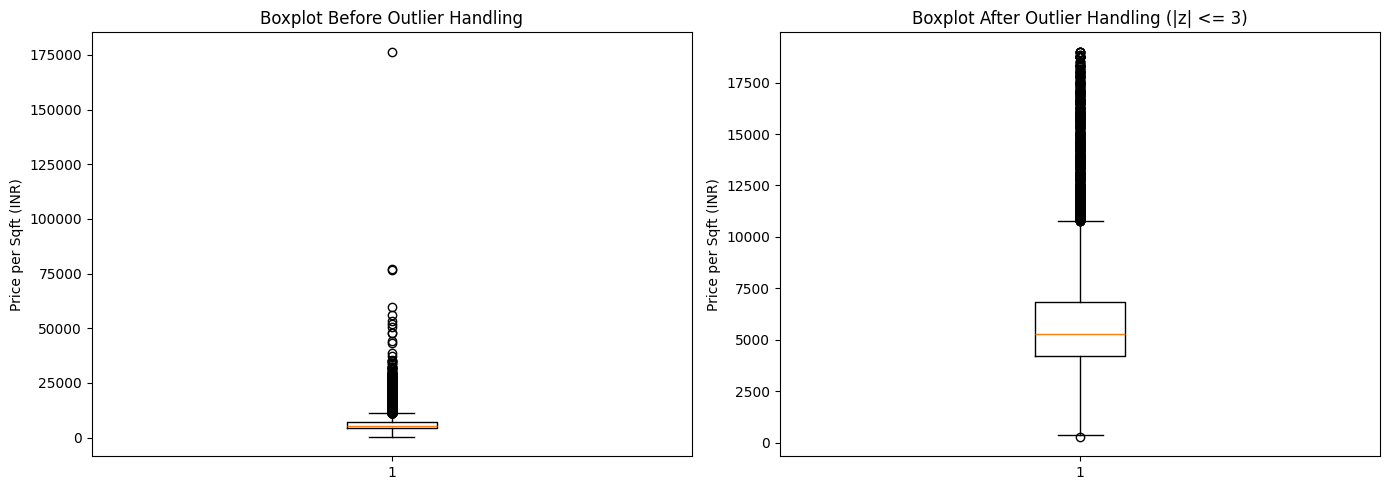

In [38]:
# YOUR CODE HERE

print("=== price_per_sqft describe BEFORE removing outliers ===")
display(df['price_per_sqft'].describe())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].boxplot(df['price_per_sqft'])
axes[0].set_title("Boxplot Before Outlier Handling")
axes[0].set_ylabel("Price per Sqft (INR)")

df = df[z_scores.abs() <= 3]

print("\n=== price_per_sqft describe AFTER removing outliers ===")
display(df['price_per_sqft'].describe())

axes[1].boxplot(df['price_per_sqft'])
axes[1].set_title("Boxplot After Outlier Handling (|z| <= 3)")
axes[1].set_ylabel("Price per Sqft (INR)")
plt.tight_layout()
plt.show()

**Your answer / justification:**

We chose **outlier removal using the Z-score method (|z| > 3)**. Real-estate prices have an inherently right-skewed distribution; the standard IQR upper fence (~₹11,048) is overly aggressive and would inappropriately discard valid listings from Bengaluru's authentic luxury markets (such as Cunningham Road, Sadashiva Nagar, and Rajaji Nagar). The Z-score threshold (|z| > 3) targets only extreme anomalies (e.g. listings priced up to ₹1,76,000/sqft due to typographical data errors) while preserving legitimate prime locality transactions.

---
## Part H: Encoding and scaling

**H1.** One-hot encode `area_type` using `pd.get_dummies`. Show the new columns.

In [39]:
# YOUR CODE HERE
area_dummies = pd.get_dummies(df['area_type'], prefix='area', dtype=int)
df = pd.concat([df, area_dummies], axis=1)

print("New area_type dummy columns:", area_dummies.columns.tolist())
display(df[area_dummies.columns].head())


New area_type dummy columns: ['area_Built-up  Area', 'area_Carpet  Area', 'area_Plot  Area', 'area_Super built-up  Area']


,area_Built-up Area,area_Carpet Area,area_Plot Area,area_Super built-up Area
0,0,0,0,1
1,0,0,1,0
2,1,0,0,0
3,0,0,0,1
4,0,0,0,1


**H2.** `location` has too many unique values to one-hot encode directly.
Keep the 10 most frequent locations, replace all others with `"Other"`, then one-hot encode. Explain why this is needed.

In [40]:
# YOUR CODE HERE
top_10_locs = df['location'].value_counts().nlargest(10).index.tolist()
print("Top 10 most frequent localities:", top_10_locs)

df['location_grouped'] = df['location'].apply(lambda x: x if x in top_10_locs else 'Other')
print("\nCounts in grouped location feature:")
display(df['location_grouped'].value_counts())

loc_dummies = pd.get_dummies(df['location_grouped'], prefix='loc', dtype=int)
df = pd.concat([df, loc_dummies], axis=1)

print("\nNew location dummy columns:", loc_dummies.columns.tolist())
display(df[loc_dummies.columns].head())


Top 10 most frequent localities: ['Whitefield', 'Sarjapur  Road', 'Electronic City', 'Kanakpura Road', 'Thanisandra', 'Yelahanka', 'Marathahalli', 'Hebbal', 'Raja Rajeshwari Nagar', 'Uttarahalli']

Counts in grouped location feature:


,count
location_grouped,
Other,9313
Whitefield,517
Sarjapur Road,373
Electronic City,280
Kanakpura Road,245
Thanisandra,230
Yelahanka,203
Marathahalli,164
Hebbal,159



New location dummy columns: ['loc_Electronic City', 'loc_Hebbal', 'loc_Kanakpura Road', 'loc_Marathahalli', 'loc_Other', 'loc_Raja Rajeshwari Nagar', 'loc_Sarjapur  Road', 'loc_Thanisandra', 'loc_Uttarahalli', 'loc_Whitefield', 'loc_Yelahanka']


,loc_Electronic City,loc_Hebbal,loc_Kanakpura Road,loc_Marathahalli,loc_Other,loc_Raja Rajeshwari Nagar,loc_Sarjapur Road,loc_Thanisandra,loc_Uttarahalli,loc_Whitefield,loc_Yelahanka
0,0,0,0,0,1,0,0,0,0,0,0
1,0,0,0,0,1,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,1,0,0
3,0,0,0,0,1,0,0,0,0,0,0
4,0,0,0,0,1,0,0,0,0,0,0


**Your answer / justification:**
Bengaluru contains hundreds of distinct localities, many having only a single listing. One-hot encoding all of them directly would cause the **Curse of Dimensionality**, adding hundreds of sparse columns that consume immense memory and cause machine learning models to overfit. Retaining the top 10 most active localities and consolidating the rest into `'Other'` preserves key market indicators while keeping the feature space compact and computationally efficient.

**H3.** Scale `total_sqft` with **min-max scaling** and `bath` with **standardization (z-score)**. Use the formulas directly. Show `describe()` of the scaled columns and confirm that min-max gives a range of 0 to 1 and standardization gives mean about 0 and std about 1.

In [41]:
# YOUR CODE HERE
min_sqft = df['total_sqft'].min()
max_sqft = df['total_sqft'].max()
df['total_sqft_minmax'] = (df['total_sqft'] - min_sqft) / (max_sqft - min_sqft)

# Standardization: (x - mean) / std
mean_bath = df['bath'].mean()
std_bath = df['bath'].std()
df['bath_standardized'] = (df['bath'] - mean_bath) / std_bath

print("=== Summary Statistics of Scaled Columns ===")
display(df[['total_sqft_minmax', 'bath_standardized']].describe())

print(f"\nConfirmation of scaling ranges:")
print(f"total_sqft_minmax min: {df['total_sqft_minmax'].min():.4f}, max: {df['total_sqft_minmax'].max():.4f} (Expected: 0 to 1)")
print(f"bath_standardized mean: {df['bath_standardized'].mean():.4f}, std: {df['bath_standardized'].std():.4f} (Expected: mean ~ 0, std ~ 1)")

=== Summary Statistics of Scaled Columns ===


,total_sqft_minmax,bath_standardized
count,11792.000000,1.179200e+04
mean,0.024703,-1.687177e-16
std,0.024164,1.000000e+00
min,0.000000,-1.457476e+00
25%,0.015677,-5.146104e-01
50%,0.019241,-5.146104e-01
75%,0.026938,4.282556e-01
max,1.000000,1.268551e+01



Confirmation of scaling ranges:
total_sqft_minmax min: 0.0000, max: 1.0000 (Expected: 0 to 1)
bath_standardized mean: -0.0000, std: 1.0000 (Expected: mean ~ 0, std ~ 1)


---
## Part I: Insights

**I1.** Find the 10 most expensive localities by **median** `price_per_sqft`, but only consider localities with at least 10 listings. Explain why median and a minimum count are used.

In [42]:
# YOUR CODE HERE
loc_stats = df.groupby('location').agg(
    listing_count=('price_per_sqft', 'count'),
    median_price_per_sqft=('price_per_sqft', 'median'),
    mean_price_per_sqft=('price_per_sqft', 'mean')
)

top_10_expensive = loc_stats[loc_stats['listing_count'] >= 10].sort_values(by='median_price_per_sqft', ascending=False).head(10)

print("Top 10 Most Expensive Localities by Median Price per Sqft (min 10 listings):")
display(top_10_expensive)

Top 10 Most Expensive Localities by Median Price per Sqft (min 10 listings):


,listing_count,median_price_per_sqft,mean_price_per_sqft
location,,,
Benson Town,15,14573.991031,12688.815074
Rajaji Nagar,94,13558.391810,12862.352908
Malleshwaram,45,12415.349887,11476.530177
1st Block Jayanagar,10,12258.569501,12359.253758
Dairy Circle,10,11904.981445,12194.861124
Sarakki Nagar,13,11171.574904,11180.696177
Cooke Town,16,10755.295429,10818.517500
Kodihalli,11,10301.353014,9529.654029
Indira Nagar,34,10234.782609,10747.682630


**Your answer / justification:**

1. **Why Median?** Real-estate pricing distributions are skewed to the right by luxury properties. The mean is pulled upward by extreme values, giving a misleading impression of standard prices, whereas the median represents the true typical property price.
2. **Why Minimum 10 Listings?** Localities with only 1 or 2 properties suffer from high variance and small-sample bias. A single luxury transaction could falsely rank an obscure area as the city's most expensive. Setting a threshold of at least 10 listings guarantees statistical reliability.

**I2.** Compare the average `price_per_sqft` across `area_type` using a bar chart.

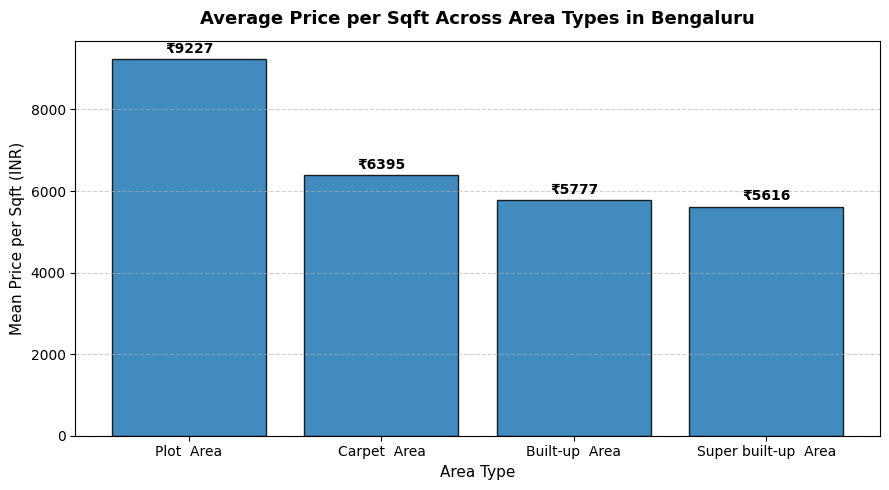

In [43]:
# YOUR CODE HERE
avg_pps_area = df.groupby('area_type')['price_per_sqft'].mean().sort_values(ascending=False)

plt.figure(figsize=(9, 5))
bars = plt.bar(avg_pps_area.index, avg_pps_area.values, color='#1f77b4', edgecolor='black', alpha=0.85)

plt.title("Average Price per Sqft Across Area Types in Bengaluru", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Area Type", fontsize=11)
plt.ylabel("Mean Price per Sqft (INR)", fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.6)

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, height + 80, f"₹{height:.0f}", ha='center', va='bottom', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()

**I3.** Write 3 recommendations for a first-time home buyer with a budget of your choice, based on your analysis. Mention at least one number from your results in each.

**Your answer / justification:**
Assuming a first-time home buyer with a **Budget of ₹50 - 75 Lakhs**:
1. **Target Suburban IT Corridors (Whitefield / Electronic City)**: These localities boast huge listing volumes and median rates around ₹4,200 to ₹5,400 per sqft. Within a ₹60–₹65 Lakh budget, a first-time buyer can comfortably acquire a spacious 1,000–1,150 sqft 2 BHK flat with full gated amenities, whereas prime central areas (e.g. Rajaji Nagar at ~₹13,500/sqft) would be completely unaffordable.
2. **Choose Super Built-up Area Over Plot Area**: The analysis reveals that *Plot Area* commands a much higher average rate (over ₹8,000/sqft), whereas *Super built-up Area* averages roughly ₹5,500/sqft. Buying in a Super built-up apartment complex gives the buyer 30% to 40% more livable area per rupee spent.
3. **Verify Adequate Sqft-per-BHK (> 450 sqft)**: The data cleaning audit identified over 700 listings with an unlivable `sqft_per_bhk` under 300 sqft. First-time buyers should verify that a 2 BHK has at least 850–900 sqft to ensure proper ventilation, living quality, and strong future resale liquidity.

---
## Before you submit

- [ ] Notebook runs from top to bottom without errors
- [ ] Every cleaning decision has a written reason
- [ ] No hard-coded answers (use code, not numbers typed by hand)
- [ ] File is named `RollNo_Name_Bengaluru.ipynb`

**Optional extra:** Add one more insight of your own (for example, the effect of `balcony` or `availability` on price) with a chart and a two-line explanation.